In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
nltk.download('all')

[nltk_data] Downloading collection 'all'
[nltk_data]    | 
[nltk_data]    | Downloading package abc to
[nltk_data]    |     C:\Users\abhir\AppData\Roaming\nltk_data...
[nltk_data]    |   Package abc is already up-to-date!
[nltk_data]    | Downloading package alpino to
[nltk_data]    |     C:\Users\abhir\AppData\Roaming\nltk_data...
[nltk_data]    |   Package alpino is already up-to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger to
[nltk_data]    |     C:\Users\abhir\AppData\Roaming\nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger is already up-
[nltk_data]    |       to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger_eng to
[nltk_data]    |     C:\Users\abhir\AppData\Roaming\nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger_eng is already
[nltk_data]    |       up-to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger_ru to
[nltk_data]    |     C:\Users\abhir\AppData\Roaming\nltk_data...
[

True

# 1. Data Exploration and Preprocessing

In [2]:
df = pd.read_csv("D:\\Data science\\Assignments\\Questions\\NLP and naviBias\\blogs.csv")
df

,Data,Labels
0,Path: cantaloupe.srv.cs.cmu.edu!magnesium.club...,alt.atheism
1,Newsgroups: alt.atheism\nPath: cantaloupe.srv....,alt.atheism
2,Path: cantaloupe.srv.cs.cmu.edu!das-news.harva...,alt.atheism
3,Path: cantaloupe.srv.cs.cmu.edu!magnesium.club...,alt.atheism
4,Xref: cantaloupe.srv.cs.cmu.edu alt.atheism:53...,alt.atheism
...,...,...
1995,Xref: cantaloupe.srv.cs.cmu.edu talk.abortion:...,talk.religion.misc
1996,Xref: cantaloupe.srv.cs.cmu.edu talk.religion....,talk.religion.misc
1997,Xref: cantaloupe.srv.cs.cmu.edu talk.origins:4...,talk.religion.misc
1998,Xref: cantaloupe.srv.cs.cmu.edu talk.religion....,talk.religion.misc


In [5]:
display(df['Labels'].value_counts())
display(df['Labels'].value_counts(normalize=True))
display(df.isnull().sum())

alt.atheism                 100
comp.graphics               100
talk.politics.misc          100
talk.politics.mideast       100
talk.politics.guns          100
soc.religion.christian      100
sci.space                   100
sci.med                     100
sci.electronics             100
sci.crypt                   100
rec.sport.hockey            100
rec.sport.baseball          100
rec.motorcycles             100
rec.autos                   100
misc.forsale                100
comp.windows.x              100
comp.sys.mac.hardware       100
comp.sys.ibm.pc.hardware    100
comp.os.ms-windows.misc     100
talk.religion.misc          100
Name: Labels, dtype: int64

alt.atheism                 0.05
comp.graphics               0.05
talk.politics.misc          0.05
talk.politics.mideast       0.05
talk.politics.guns          0.05
soc.religion.christian      0.05
sci.space                   0.05
sci.med                     0.05
sci.electronics             0.05
sci.crypt                   0.05
rec.sport.hockey            0.05
rec.sport.baseball          0.05
rec.motorcycles             0.05
rec.autos                   0.05
misc.forsale                0.05
comp.windows.x              0.05
comp.sys.mac.hardware       0.05
comp.sys.ibm.pc.hardware    0.05
comp.os.ms-windows.misc     0.05
talk.religion.misc          0.05
Name: Labels, dtype: float64

Data      0
Labels    0
dtype: int64

In [6]:
df = df.drop_duplicates()
df


,Data,Labels
0,Path: cantaloupe.srv.cs.cmu.edu!magnesium.club...,alt.atheism
1,Newsgroups: alt.atheism\nPath: cantaloupe.srv....,alt.atheism
2,Path: cantaloupe.srv.cs.cmu.edu!das-news.harva...,alt.atheism
3,Path: cantaloupe.srv.cs.cmu.edu!magnesium.club...,alt.atheism
4,Xref: cantaloupe.srv.cs.cmu.edu alt.atheism:53...,alt.atheism
...,...,...
1995,Xref: cantaloupe.srv.cs.cmu.edu talk.abortion:...,talk.religion.misc
1996,Xref: cantaloupe.srv.cs.cmu.edu talk.religion....,talk.religion.misc
1997,Xref: cantaloupe.srv.cs.cmu.edu talk.origins:4...,talk.religion.misc
1998,Xref: cantaloupe.srv.cs.cmu.edu talk.religion....,talk.religion.misc


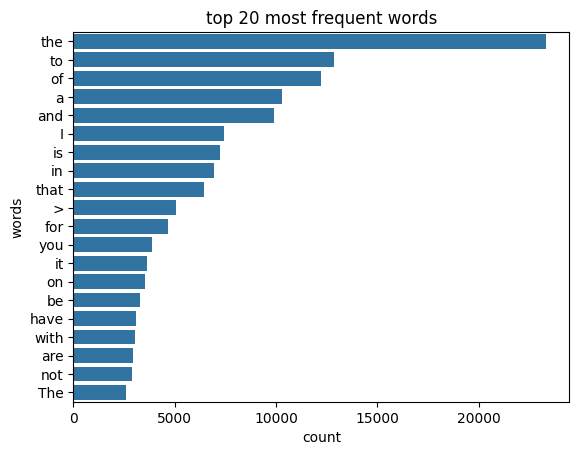

In [7]:
from collections import Counter

all_words = " ".join(df['Data'].values).split()
word_counts = Counter(all_words)
common_words = word_counts.most_common(20)
common_words_df = pd.DataFrame(common_words, columns=['words', 'count'])
sns.barplot(data=common_words_df, x='count', y='words')
plt.title("top 20 most frequent words")
plt.show()

In [8]:
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

def clean(doc):
    regexp = "[^a-zA-Z]"
    doc = re.sub(regexp, " ", doc)
    doc = doc.lower()
    tokens = nltk.word_tokenize(doc)
    stop_words = list(set(stopwords.words('english')))
    custom_stop_words = ['path','newsgroups','xref']
    stop_words = custom_stop_words + stop_words
    filtered_tokens = [word for word in tokens if word not in stop_words]
    lemmatizer = WordNetLemmatizer()
    lemmatized_tokens = [lemmatizer.lemmatize(token) for token in filtered_tokens]
    return " ".join(lemmatized_tokens)

def tokenizer(doc):
    return nltk.word_tokenize(doc)

# 2. Naive Bayes Model for Text Classification

In [10]:
X = df['Data']
Y = df['Labels']

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

X_train = pd.DataFrame(X_train)
X_test = pd.DataFrame(X_test)
Y_train = pd.DataFrame(Y_train)
Y_test = pd.DataFrame(Y_test)

display(X_train.shape)
display(X_test.shape)
display(Y_train.shape)
display(Y_test.shape)


(1600, 1)

(400, 1)

(1600, 1)

(400, 1)

In [12]:
from sklearn.feature_extraction.text import CountVectorizer

bow_vect = CountVectorizer(preprocessor=clean, tokenizer=tokenizer, binary=True, ngram_range=(1,1))

%time X_train_transform = bow_vect.fit_transform(X_train['Data'])
print("*****************************************")
print(f"shape of X_train_transformed (# of docs, # of unique vocabolary): {X_train_transform.shape}")
print("*****************************************")
print(f"type of X_train_transform (CSR format): {type(X_train_transform)}")
print("*****************************************")
print(f"vocabulary learned: {bow_vect.get_feature_names_out()}")

c:\Users\abhir\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\feature_extraction\text.py:525: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


CPU times: total: 8.23 s
Wall time: 8.5 s
*****************************************
shape of X_train_transformed (# of docs, # of unique vocabolary): (1600, 31564)
*****************************************
type of X_train_transform (CSR format): <class 'scipy.sparse._csr.csr_matrix'>
*****************************************
vocabulary learned: ['aa' 'aaa' 'aaaaarrrrgh' ... 'zzd' 'zzs' 'zzx']


In [13]:
new_train_ind_var = pd.DataFrame(X_train_transform.toarray())
new_train_ind_var.head()

,0,1,2,3,4,5,6,7,8,9,...,31554,31555,31556,31557,31558,31559,31560,31561,31562,31563
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [15]:
from tqdm import tqdm, tqdm_notebook
tqdm.pandas()

In [16]:
X_train['Clean_text'] = X_train['Data'].progress_apply(lambda doc: clean(doc))
X_train.head()

100%|██████████| 1600/1600 [00:04<00:00, 325.69it/s]


,Data,Clean_text
968,Path: cantaloupe.srv.cs.cmu.edu!crabapple.srv....,cantaloupe srv c cmu edu crabapple srv c cmu e...
240,Xref: cantaloupe.srv.cs.cmu.edu comp.unix.misc...,cantaloupe srv c cmu edu comp unix misc comp o...
819,Path: cantaloupe.srv.cs.cmu.edu!rochester!corn...,cantaloupe srv c cmu edu rochester cornell bat...
692,Path: cantaloupe.srv.cs.cmu.edu!rochester!udel...,cantaloupe srv c cmu edu rochester udel gatech...
420,Newsgroups: comp.sys.mac.hardware\nPath: canta...,comp sys mac hardware cantaloupe srv c cmu edu...


In [17]:
X_test_transform = bow_vect.transform(X_test['Data'])
X_test_transform.shape

(400, 31564)

In [18]:
from sklearn.naive_bayes import MultinomialNB
from sklearn import metrics

classifier_nb = MultinomialNB()
classifier_nb.fit(X_train_transform, Y_train)

c:\Users\abhir\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:1300: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


MultinomialNB()

In [19]:
y_pred_train = classifier_nb.predict(X_train_transform)
y_pred_test = classifier_nb.predict(X_test_transform)

In [22]:
metrics.accuracy_score(Y_train, y_pred_train)

0.99625

In [21]:
metrics.accuracy_score(Y_test, y_pred_test)

0.8

# 3. Sentiment Analysis

In [24]:
# Sentiment Analysis
from textblob import TextBlob
def get_sentiment(text):
    analysis = TextBlob(text)
    return analysis.sentiment.polarity

X_train['Sentiment'] = X_train['Clean_text'].apply(get_sentiment)
X_test['Sentiment'] = X_test['Data'].apply(get_sentiment)

display(X_train.head())
display(X_test.head())

,Data,Clean_text,Sentiment
968,Path: cantaloupe.srv.cs.cmu.edu!crabapple.srv....,cantaloupe srv c cmu edu crabapple srv c cmu e...,-0.061667
240,Xref: cantaloupe.srv.cs.cmu.edu comp.unix.misc...,cantaloupe srv c cmu edu comp unix misc comp o...,0.041980
819,Path: cantaloupe.srv.cs.cmu.edu!rochester!corn...,cantaloupe srv c cmu edu rochester cornell bat...,-0.093981
692,Path: cantaloupe.srv.cs.cmu.edu!rochester!udel...,cantaloupe srv c cmu edu rochester udel gatech...,0.059259
420,Newsgroups: comp.sys.mac.hardware\nPath: canta...,comp sys mac hardware cantaloupe srv c cmu edu...,0.047619


,Data,Sentiment
1860,Xref: cantaloupe.srv.cs.cmu.edu misc.headlines...,0.091369
353,Newsgroups: comp.sys.ibm.pc.hardware\nPath: ca...,0.141414
1333,Xref: cantaloupe.srv.cs.cmu.edu sci.energy:156...,0.033968
905,Newsgroups: rec.sport.baseball\nPath: cantalou...,0.212381
1289,Newsgroups: sci.electronics\nPath: cantaloupe....,0.229167


# 4. Evaluation

In [25]:
def categorize_sentiment(score):
    if score > 0:
        return 'Positive'
    elif score < 0:
        return 'Negative'
    else:
        return 'Neutral'

df['Sentiment_Category'] = df['Data'].apply(lambda x: categorize_sentiment(get_sentiment(x)))
display(df['Sentiment_Category'].value_counts())

sentiment_distribution = df.groupby('Labels')['Sentiment_Category'].value_counts().unstack(fill_value=0)
display(sentiment_distribution)

print("\nSummary of Sentiment Distribution by Category:")
print("----------------------------------------------")
for index, row in sentiment_distribution.iterrows():
    print(f"Category: {index}")
    print(f"  Positive: {row.get('Positive', 0)}")
    print(f"  Negative: {row.get('Negative', 0)}")
    print(f"  Neutral: {row.get('Neutral', 0)}")
    print("-" * 20)

Positive    1543
Negative     457
Name: Sentiment_Category, dtype: int64

Sentiment_Category,Negative,Positive
Labels,,
alt.atheism,23,77
comp.graphics,24,76
comp.os.ms-windows.misc,22,78
comp.sys.ibm.pc.hardware,20,80
comp.sys.mac.hardware,24,76
comp.windows.x,27,73
misc.forsale,16,84
rec.autos,17,83
rec.motorcycles,26,74



Summary of Sentiment Distribution by Category:
----------------------------------------------
Category: alt.atheism
  Positive: 77
  Negative: 23
  Neutral: 0
--------------------
Category: comp.graphics
  Positive: 76
  Negative: 24
  Neutral: 0
--------------------
Category: comp.os.ms-windows.misc
  Positive: 78
  Negative: 22
  Neutral: 0
--------------------
Category: comp.sys.ibm.pc.hardware
  Positive: 80
  Negative: 20
  Neutral: 0
--------------------
Category: comp.sys.mac.hardware
  Positive: 76
  Negative: 24
  Neutral: 0
--------------------
Category: comp.windows.x
  Positive: 73
  Negative: 27
  Neutral: 0
--------------------
Category: misc.forsale
  Positive: 84
  Negative: 16
  Neutral: 0
--------------------
Category: rec.autos
  Positive: 83
  Negative: 17
  Neutral: 0
--------------------
Category: rec.motorcycles
  Positive: 74
  Negative: 26
  Neutral: 0
--------------------
Category: rec.sport.baseball
  Positive: 71
  Negative: 29
  Neutral: 0
----------------

In [26]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

print("Training Set Evaluation:")
print(f"Accuracy: {accuracy_score(Y_train, y_pred_train):.4f}")
print(f"Precision: {precision_score(Y_train, y_pred_train, average='weighted'):.4f}")
print(f"Recall: {recall_score(Y_train, y_pred_train, average='weighted'):.4f}")
print(f"F1-score: {f1_score(Y_train, y_pred_train, average='weighted'):.4f}")
print("\nClassification Report:\n", classification_report(Y_train, y_pred_train))
print("\nConfusion Matrix:\n", confusion_matrix(Y_train, y_pred_train))

print("\n" + "="*50 + "\n")
print("Testing Set Evaluation:")
print(f"Accuracy: {accuracy_score(Y_test, y_pred_test):.4f}")
print(f"Precision: {precision_score(Y_test, y_pred_test, average='weighted'):.4f}")
print(f"Recall: {recall_score(Y_test, y_pred_test, average='weighted'):.4f}")
print(f"F1-score: {f1_score(Y_test, y_pred_test, average='weighted'):.4f}")
print("\nClassification Report:\n", classification_report(Y_test, y_pred_test))
print("\nConfusion Matrix:\n", confusion_matrix(Y_test, y_pred_test))

Training Set Evaluation:
Accuracy: 0.9962
Precision: 0.9963
Recall: 0.9962
F1-score: 0.9962

Classification Report:
                           precision    recall  f1-score   support

             alt.atheism       0.98      0.99      0.98        82
           comp.graphics       1.00      0.99      0.99        82
 comp.os.ms-windows.misc       1.00      1.00      1.00        78
comp.sys.ibm.pc.hardware       0.99      1.00      0.99        75
   comp.sys.mac.hardware       1.00      1.00      1.00        79
          comp.windows.x       1.00      1.00      1.00        75
            misc.forsale       1.00      1.00      1.00        82
               rec.autos       1.00      1.00      1.00        82
         rec.motorcycles       1.00      1.00      1.00        84
      rec.sport.baseball       1.00      0.99      0.99        82
        rec.sport.hockey       0.99      1.00      0.99        85
               sci.crypt       1.00      1.00      1.00        81
         sci.electronics

# Discussion of Model Performance and Sentiment Analysis

### Naive Bayes Classifier Performance

The Multinomial Naive Bayes classifier achieved a high accuracy of 0.9962 on the training set, indicating that the model learned the training data very well. However, the accuracy on the testing set is significantly lower at 0.8000. This suggests that the model might be overfitting to the training data and may not generalize well to unseen data.

The precision, recall, and F1-score on the testing set are also lower than on the training set, further supporting the observation of overfitting. The confusion matrix provides a detailed view of the misclassifications, showing which categories are being confused with each other. Some categories, like "soc.religion.christian" and "sci.space", have high precision and recall, while others, like "comp.windows.x" and "talk.politics.misc", have lower scores, indicating that the model struggles more with these categories.

Challenges encountered during the classification process include:
- **Data Sparsity:** Text data, when vectorized using methods like Bag-of-Words, often results in high-dimensional but sparse matrices, which can impact model performance.
- **Feature Engineering:** Choosing the right text preprocessing steps and vectorization method is crucial and can significantly affect the model's ability to learn from the data.
- **Model Selection:** While Naive Bayes is a good baseline model for text classification, it might not be the most suitable for this specific dataset, given the performance difference between training and testing sets.

### Sentiment Analysis Results and Implications

The sentiment analysis revealed that the majority of blog posts in this dataset have a positive sentiment (1543 positive vs. 457 negative, with no neutral sentiments based on the categorization threshold).

Examining the sentiment distribution across different categories shows variations:
- Categories like "soc.religion.christian" and "misc.forsale" have a higher proportion of positive sentiments.
- Categories like "rec.sport.hockey" and "talk.politics.guns" have a relatively higher proportion of negative sentiments compared to others.

The sentiment analysis provides valuable insights into the emotional tone of discussions within different blog categories. This information could potentially be used as an additional feature in the text classification model to improve its performance, especially for differentiating between categories with similar vocabulary but different emotional expressions. For example, categories with more polarized or negative discussions might be better distinguished by including sentiment as a feature.

Overall, the sentiment analysis complements the topic-based classification by adding another dimension to understanding the content of the blog posts.